# StreamLoop · Ajuste sistemático del clasificador de cancelación (churn)

**Petición del tech lead:** demostrar que el modelo es la mejor configuración que podemos encontrar, no "lo primero
que salió de `.fit()`", y explicar **por qué** elegimos la versión final.

**Proceso:**

1. Línea base: pipeline con hiperparámetros por defecto, evaluado una vez en test.
2. Búsqueda amplia y económica con `RandomizedSearchCV`.
3. Búsqueda focalizada con `GridSearchCV` alrededor de lo mejor de la anterior.
4. Revisión de `cv_results_`: no solo el mejor promedio, también cuánto varía entre folds.
5. Evaluación final en test (segunda y última vez que lo tocamos) y comparación con la línea base.

**Reglas que seguimos para que el tuning sea válido:**

- Dividimos train/test **antes** de cualquier otra cosa.
- Todo el preprocesamiento vive **dentro del `Pipeline`**, así que en cada fold se ajusta solo con los datos de entrenamiento de ese fold.
- Las búsquedas **solo ven train**. El test se usa exactamente dos veces.

## 0. Configuración

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import randint
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, f1_score, fbeta_score, make_scorer,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Carga y limpieza mínima

In [2]:
raw = pd.read_csv(DATA_URL)
print("Filas x columnas:", raw.shape)
print("Nulos detectados por pandas:", int(raw.isna().sum().sum()))
print("\nTipos de columna:", raw.dtypes.value_counts().to_dict())
print("Distribución de Churn:", raw["Churn"].value_counts(normalize=True).round(3).to_dict())
raw.head(3)

Filas x columnas: (7043, 21)
Nulos detectados por pandas: 0

Tipos de columna: {dtype('O'): 18, dtype('int64'): 2, dtype('float64'): 1}
Distribución de Churn: {'No': 0.735, 'Yes': 0.265}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


pandas no detecta nulos, pero hay que mirar dos cosas antes de fiarse:

In [3]:
total_charges = pd.to_numeric(raw["TotalCharges"], errors="coerce")
blank = total_charges.isna()
print("TotalCharges se leyó como texto:", raw["TotalCharges"].dtype)
print("Valores que no son número:", int(blank.sum()), "→", raw.loc[blank, "TotalCharges"].unique())
print("Antigüedad (tenure) de esos clientes:", raw.loc[blank, "tenure"].unique())
print("customerID único:", raw["customerID"].is_unique)

TotalCharges se leyó como texto: object
Valores que no son número: 11 → [' ']
Antigüedad (tenure) de esos clientes: [0]
customerID único: True


**Limpieza mínima (solo lo imprescindible, fuera del pipeline):**

- `TotalCharges` llega como texto porque **11 clientes** tienen un espacio en blanco: son altas recientes
  (`tenure = 0`) que aún no han recibido ninguna factura. Lo convertimos a número y esos valores quedan como **vacíos**.
  **No los rellenamos aquí**: la imputación se hace dentro del pipeline, aprendiendo solo de train.
- `customerID` es un identificador: no aporta información para predecir, así que lo quitamos.
- `Churn` (`Yes`/`No`) pasa a **1 / 0**. La clase positiva (1) es **el cliente que cancela**.

El resto del preprocesamiento (imputar, escalar, codificar categorías) depende de los datos y por eso va dentro del `Pipeline`.

In [4]:
df = raw.drop(columns="customerID").copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = (df["Churn"] == "Yes").astype(int)

X = df.drop(columns="Churn")
y = df["Churn"]

NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL = [c for c in X.columns if c not in NUMERIC]  # incluye SeniorCitizen (0/1)

print(f"Numéricas ({len(NUMERIC)}):", NUMERIC)
print(f"Categóricas ({len(CATEGORICAL)}):", CATEGORICAL)
print("Vacíos tras convertir:", X.isna().sum()[lambda s: s > 0].to_dict())

Numéricas (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Vacíos tras convertir: {'TotalCharges': 11}


## 2. División train / test (antes de todo lo demás)

80 / 20, **estratificada** para mantener la misma proporción de cancelaciones (~26,5 %) en ambos conjuntos.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED,
)
print(f"Train: {len(X_train)} clientes · churn {y_train.mean():.1%}")
print(f"Test:  {len(X_test)} clientes · churn {y_test.mean():.1%}")

Train: 5634 clientes · churn 26.5%
Test:  1409 clientes · churn 26.5%


## 3. Qué significa "bueno" aquí: la métrica

**Prioridad de negocio:** a StreamLoop le cuesta mucho más un cliente que cancela **sin ser detectado**
(falso negativo) que ofrecer una retención a alguien que no la necesitaba (falso positivo).

| Métrica | Problema para este caso |
|---|---|
| Accuracy (la de sklearn por defecto) | Con un 73,5 % de clientes que no cancelan, un modelo que dice "nadie cancela" ya acierta el 73,5 % y no detecta a ninguno |
| Recall solo | Se maximiza marcando a **todos** como "cancela" (recall = 100 %): inútil, porque se ofrecería retención a todo el mundo |
| F1 | Pesa igual precisión y recall, pero el negocio dice que no valen lo mismo |
| **F2 (elegida)** | Media armónica que da **el doble de peso al recall** que a la precisión: premia detectar cancelaciones sin permitir marcar a todo el mundo |

Usaremos **F2** como `scoring` en ambas búsquedas y como métrica principal en test. También registraremos recall,
precisión, F1, accuracy y ROC-AUC para la línea base y para el modelo final, con exactamente las mismas métricas.

In [6]:
f2_scorer = make_scorer(fbeta_score, beta=2)


def evaluate(model, X, y):
    """
    Métricas en un conjunto dado. Misma función para la línea base y el modelo final.
    Devuelve también las predicciones, para dibujar la matriz de confusión sin volver a pasar el test por el modelo.
    """
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    metrics = {
        "F2": fbeta_score(y, pred, beta=2),
        "Recall": recall_score(y, pred),
        "Precisión": precision_score(y, pred),
        "F1": f1_score(y, pred),
        "Accuracy": accuracy_score(y, pred),
        "ROC-AUC": roc_auc_score(y, proba),
        "Churners detectados": f"{int(((pred == 1) & (y == 1)).sum())} de {int(y.sum())}",
        "Alertas emitidas": int(pred.sum()),
    }
    return metrics, pred

## 4. Línea base: pipeline con hiperparámetros por defecto

**Clasificador:** `RandomForestClassifier`. Tiene hiperparámetros con un efecto claro e interpretable (número de árboles,
profundidad, tamaño mínimo de las hojas, variables por división…) y soporta `class_weight`, que permite compensar el
desequilibrio de clases: algo muy relevante cuando nos importa el recall.

**Preprocesamiento dentro del pipeline:**

- Numéricas: imputación con la **mediana** (para los 11 `TotalCharges` vacíos) + estandarización.
- Categóricas: **one-hot encoding**, ignorando categorías nuevas que pudieran aparecer en test.

In [7]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

baseline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(random_state=SEED)),  # hiperparámetros por defecto
])
baseline

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [8]:
baseline.fit(X_train, y_train)

# PRIMER uso del test set (de dos)
baseline_metrics, baseline_pred = evaluate(baseline, X_test, y_test)
pd.Series(baseline_metrics, name="Línea base (test)").to_frame()

,Línea base (test)
F2,0.498599
Recall,0.475936
Precisión,0.615917
F1,0.536953
Accuracy,0.782115
ROC-AUC,0.817581
Churners detectados,178 de 374
Alertas emitidas,289


La línea base parece aceptable en accuracy, pero en lo que importa al negocio se queda corta: **deja escapar a
más de la mitad de los clientes que cancelan**. Es exactamente el tipo de "buen puntaje" que preocupa al tech lead.

A partir de aquí el test set queda **cerrado** hasta la evaluación final.

## 5. Búsqueda amplia: `RandomizedSearchCV`

**Espacio de búsqueda**, basado en lo que `RandomForestClassifier` realmente soporta:

| Hiperparámetro | Rango | Qué controla |
|---|---|---|
| `n_estimators` | 100–600 | Número de árboles (más = más estable, más lento) |
| `max_depth` | None, 4–20 | Profundidad máxima: limita la complejidad de cada árbol |
| `min_samples_split` | 2–30 | Mínimo de muestras para dividir un nodo |
| `min_samples_leaf` | 1–20 | Mínimo de muestras por hoja: suaviza las predicciones |
| `max_features` | sqrt, log2, 0,3, 0,5, 0,7 | Variables candidatas en cada división: diversidad entre árboles |
| `class_weight` | None, balanced, balanced_subsample | Peso extra a la clase minoritaria (churn) |

**Validación cruzada:** 5 folds estratificados con barajado fijo, los mismos en todas las búsquedas para que los
resultados sean comparables. 60 combinaciones aleatorias, `n_jobs=-1`, `scoring` = F2 y `refit=True`.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

param_distributions = {
    "model__n_estimators": randint(100, 601),
    "model__max_depth": [None, 4, 6, 8, 10, 12, 16, 20],
    "model__min_samples_split": randint(2, 31),
    "model__min_samples_leaf": randint(1, 21),
    "model__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
}

random_search = RandomizedSearchCV(
    estimator=baseline,
    param_distributions=param_distributions,
    n_iter=60,
    scoring=f2_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True,
    random_state=SEED,
    return_train_score=True,
)

start = time.perf_counter()
random_search.fit(X_train, y_train)  # solo train
print(f"RandomizedSearchCV: {len(random_search.cv_results_['params'])} combinaciones x 5 folds "
      f"en {(time.perf_counter() - start) / 60:.1f} min")
print(f"Mejor F2 medio en CV: {random_search.best_score_:.4f}")
random_search.best_params_

RandomizedSearchCV: 60 combinaciones x 5 folds en 5.4 min
Mejor F2 medio en CV: 0.7226


{'model__class_weight': 'balanced_subsample',
 'model__max_depth': 6,
 'model__max_features': 0.3,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 11,
 'model__n_estimators': 144}

In [10]:
FOLD_COLS = [f"split{i}_test_score" for i in range(5)]


def results_table(search, top=10):
    """Tabla de cv_results_ con media, desviación, rango entre folds y sobreajuste (train - CV)."""
    res = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame({
        "rank": res["rank_test_score"],
        "F2 medio": res["mean_test_score"],
        "desv. folds": res["std_test_score"],
        "peor fold": res[FOLD_COLS].min(axis=1),
        "mejor fold": res[FOLD_COLS].max(axis=1),
        "train - CV": res["mean_train_score"] - res["mean_test_score"],
    })
    params = pd.DataFrame(res["params"].tolist()).rename(columns=lambda c: c.replace("model__", ""))
    return pd.concat([table, params], axis=1).sort_values("rank").head(top).round(4)


display(results_table(random_search))

,rank,F2 medio,desv. folds,peor fold,mejor fold,train - CV,class_weight,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
29,1,0.7226,0.0166,0.6950,0.7450,0.0339,balanced_subsample,6.0,0.3,2,11,144
56,2,0.7205,0.0202,0.6883,0.7509,0.0302,balanced_subsample,6.0,sqrt,1,17,559
34,3,0.7199,0.0190,0.6886,0.7443,0.0124,balanced_subsample,4.0,0.5,15,28,473
15,4,0.7198,0.0197,0.6863,0.7430,0.0129,balanced,4.0,0.5,14,17,370
46,5,0.7197,0.0169,0.6954,0.7482,0.0068,balanced_subsample,4.0,sqrt,11,29,540
6,6,0.7196,0.0188,0.6881,0.7446,0.0123,balanced_subsample,4.0,0.5,16,16,289
26,7,0.7194,0.0163,0.6939,0.7404,0.0129,balanced,4.0,0.5,13,20,162
20,8,0.7193,0.0216,0.6865,0.7531,0.0292,balanced_subsample,6.0,sqrt,5,11,330
23,9,0.7184,0.0192,0.6820,0.7381,0.0394,balanced,6.0,0.3,1,4,200
58,10,0.7182,0.0239,0.6831,0.7580,0.0282,balanced_subsample,6.0,log2,1,29,466


### 5.1 ¿Qué nos dice la búsqueda aleatoria?

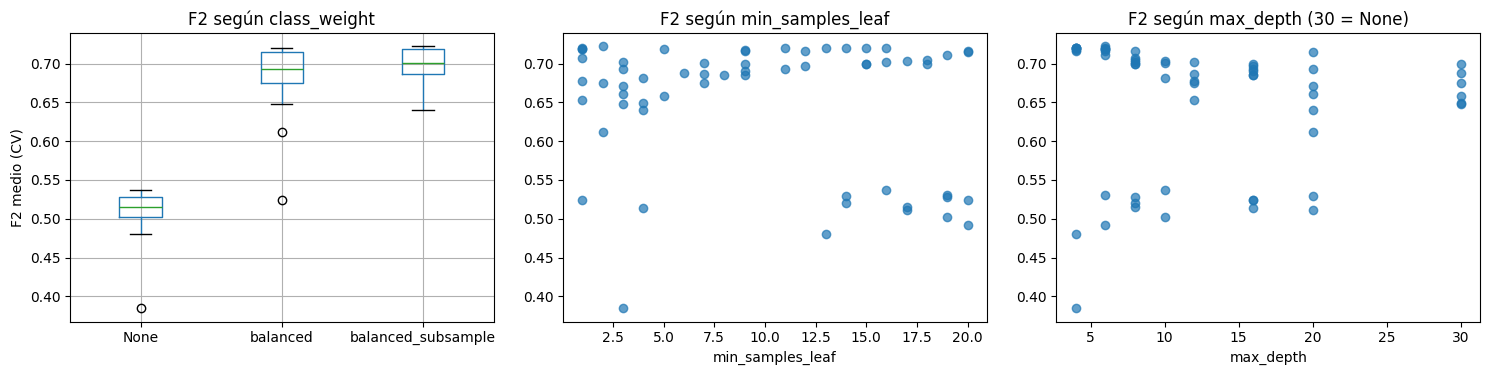

Valores en las 10 mejores combinaciones:
  class_weight: {'balanced_subsample': 7, 'balanced': 3}
  max_features: {'0.5': 4, 'sqrt': 3, '0.3': 2, 'log2': 1}
  max_depth: {'6.0': 5, '4.0': 5}
  n_estimators: mín 144 · mediana 350 · máx 559
  min_samples_leaf: mín 1 · mediana 8 · máx 16
  min_samples_split: mín 4 · mediana 17 · máx 29


In [11]:
rs = pd.DataFrame(random_search.cv_results_)
rs_params = pd.DataFrame(rs["params"].tolist()).rename(columns=lambda c: c.replace("model__", ""))
rs_params["F2"] = rs["mean_test_score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rs_params.assign(cw=rs_params["class_weight"].astype(str)).boxplot(column="F2", by="cw", ax=axes[0])
axes[0].set(title="F2 según class_weight", xlabel="", ylabel="F2 medio (CV)")
axes[1].scatter(rs_params["min_samples_leaf"], rs_params["F2"], alpha=0.7)
axes[1].set(title="F2 según min_samples_leaf", xlabel="min_samples_leaf")
depth = rs_params["max_depth"].fillna(30)
axes[2].scatter(depth, rs_params["F2"], alpha=0.7)
axes[2].set(title="F2 según max_depth (30 = None)", xlabel="max_depth")
plt.suptitle("")
plt.tight_layout()
plt.show()

top = rs_params.sort_values("F2", ascending=False).head(10)
print("Valores en las 10 mejores combinaciones:")
for p in ["class_weight", "max_features", "max_depth"]:
    print(f"  {p}: {top[p].astype(str).value_counts().to_dict()}")
for p in ["n_estimators", "min_samples_leaf", "min_samples_split"]:
    print(f"  {p}: mín {top[p].min()} · mediana {int(top[p].median())} · máx {top[p].max()}")

**Lo que aprendemos de las 60 combinaciones:**

- **`class_weight` es el factor decisivo.** Las 10 mejores combinaciones usan `balanced` o `balanced_subsample`.
  Sin compensar el desequilibrio, el bosque apenas marca cancelaciones: el F2 mediano cae de ~0,70 a ~0,51.
- **Árboles poco profundos funcionan mejor:** las 10 mejores tienen `max_depth` 4 o 6. Los árboles sin límite
  (el valor por defecto) memorizan train y generalizan peor.
- **`max_features` y `n_estimators` importan poco:** hay valores muy distintos entre las mejores
  (de 144 a 559 árboles). Las 10 primeras están separadas por solo 0,004 puntos de F2, mucho menos que
  la desviación entre folds (~0,02): a partir de aquí las diferencias son ruido.

**Región a refinar:** `balanced_subsample`, `max_features = 0.3`, profundidad entre 4 y 8, hojas pequeñas y número de árboles
alrededor de 144.

## 6. Búsqueda focalizada: `GridSearchCV`

Acotamos el espacio alrededor de la mejor configuración aleatoria:

- **Variables categóricas** (`class_weight`, `max_features`): fijamos el valor ganador.
- **Variables numéricas**: probamos el valor ganador y sus vecinos para refinar.
- `min_samples_split` se fija: con hojas de tamaño mínimo ya acotado su efecto es secundario.

La rejilla se construye a partir de `best_params_` de la búsqueda aleatoria, así el proceso es reproducible.

In [12]:
best_rs = {k.replace("model__", ""): v for k, v in random_search.best_params_.items()}


def neighbours(value, step, minimum):
    """Valor ganador y sus vecinos (sin bajar del mínimo permitido)."""
    return sorted({max(minimum, value - step), value, value + step})


depth = best_rs["max_depth"]
param_grid = {
    "model__n_estimators": neighbours(best_rs["n_estimators"], 100, 100),
    "model__max_depth": [None, 16, 20] if depth is None else neighbours(depth, 2, 2),
    "model__min_samples_leaf": neighbours(best_rs["min_samples_leaf"], 3, 1),
    "model__min_samples_split": [best_rs["min_samples_split"]],
    "model__max_features": [best_rs["max_features"]],
    "model__class_weight": [best_rs["class_weight"]],
}
n_combos = int(np.prod([len(v) for v in param_grid.values()]))
print(f"Rejilla focalizada: {n_combos} combinaciones")
{k.replace("model__", ""): v for k, v in param_grid.items()}

Rejilla focalizada: 27 combinaciones


{'n_estimators': [100, 144, 244],
 'max_depth': [4, 6, 8],
 'min_samples_leaf': [1, 2, 5],
 'min_samples_split': [11],
 'max_features': [0.3],
 'class_weight': ['balanced_subsample']}

In [13]:
grid_search = GridSearchCV(
    estimator=baseline,
    param_grid=param_grid,
    scoring=f2_scorer,
    cv=cv,                 # mismos folds que la búsqueda aleatoria
    n_jobs=-1,
    refit=True,            # reentrena el mejor sobre todo train: no lo hacemos a mano
    return_train_score=True,
)

start = time.perf_counter()
grid_search.fit(X_train, y_train)  # solo train
print(f"GridSearchCV: {n_combos} combinaciones x 5 folds en {(time.perf_counter() - start) / 60:.1f} min")
print(f"Mejor F2 medio en CV: {grid_search.best_score_:.4f}  "
      f"(búsqueda aleatoria: {random_search.best_score_:.4f})")
grid_search.best_params_

GridSearchCV: 27 combinaciones x 5 folds en 1.0 min
Mejor F2 medio en CV: 0.7226  (búsqueda aleatoria: 0.7226)


{'model__class_weight': 'balanced_subsample',
 'model__max_depth': 6,
 'model__max_features': 0.3,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 11,
 'model__n_estimators': 144}

## 7. Revisión de `cv_results_`: promedio **y** estabilidad

El mejor promedio no basta: un candidato con F2 alto pero que oscila mucho entre folds es menos fiable en producción.
Revisamos los mejores candidatos de la rejilla con su desviación, su peor y mejor fold, y la diferencia
train − CV (una diferencia grande indica sobreajuste).

,rank,F2 medio,desv. folds,peor fold,mejor fold,train - CV,class_weight,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
13,1,0.7226,0.0166,0.6950,0.7450,0.0339,balanced_subsample,6,0.3,2,11,144
14,2,0.7204,0.0184,0.6849,0.7373,0.0359,balanced_subsample,6,0.3,2,11,244
12,3,0.7201,0.0130,0.6951,0.7321,0.0360,balanced_subsample,6,0.3,2,11,100
2,4,0.7200,0.0263,0.6762,0.7578,0.0140,balanced_subsample,4,0.3,1,11,244
5,5,0.7199,0.0263,0.6762,0.7578,0.0144,balanced_subsample,4,0.3,2,11,244
6,6,0.7193,0.0255,0.6758,0.7534,0.0145,balanced_subsample,4,0.3,5,11,100
3,7,0.7192,0.0254,0.6758,0.7534,0.0141,balanced_subsample,4,0.3,2,11,100
0,7,0.7192,0.0254,0.6758,0.7534,0.0141,balanced_subsample,4,0.3,1,11,100
11,9,0.7192,0.0187,0.6836,0.7377,0.0385,balanced_subsample,6,0.3,1,11,244
8,10,0.7191,0.0257,0.6762,0.7553,0.0150,balanced_subsample,4,0.3,5,11,244


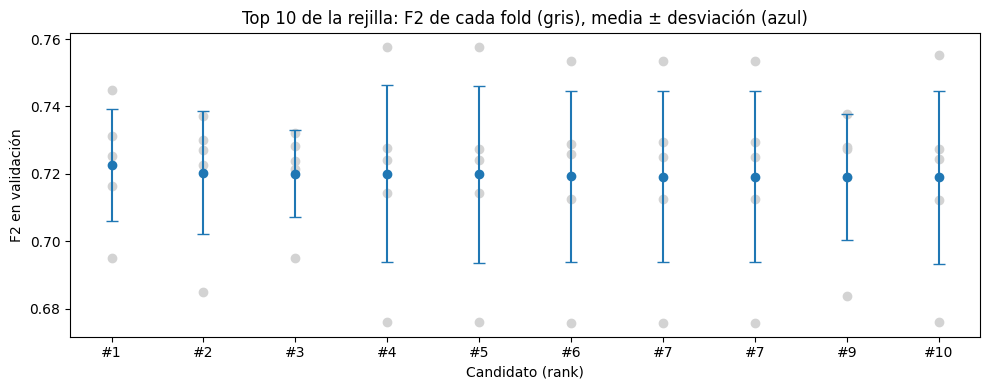

In [14]:
grid_table = results_table(grid_search, top=10)
display(grid_table)

gs = pd.DataFrame(grid_search.cv_results_).sort_values("rank_test_score").head(10)
fig, ax = plt.subplots(figsize=(10, 4))
for pos, (_, row) in enumerate(gs.iterrows()):
    folds = row[FOLD_COLS].astype(float).values
    ax.scatter([pos] * 5, folds, color="lightgray", zorder=1)
    ax.errorbar(pos, row["mean_test_score"], yerr=row["std_test_score"], fmt="o", color="C0", capsize=4, zorder=2)
ax.set_xticks(range(len(gs)))
ax.set_xticklabels([f"#{int(r)}" for r in gs["rank_test_score"]])
ax.set(title="Top 10 de la rejilla: F2 de cada fold (gris), media ± desviación (azul)",
       xlabel="Candidato (rank)", ylabel="F2 en validación")
plt.tight_layout()
plt.show()

In [15]:
best_idx = grid_search.best_index_
res = pd.DataFrame(grid_search.cv_results_)
best_mean, best_std = res.loc[best_idx, ["mean_test_score", "std_test_score"]]

# ¿Hay algún candidato prácticamente igual de bueno (dentro de un error estándar) y más estable?
std_error = best_std / np.sqrt(5)
close = res[res["mean_test_score"] >= best_mean - std_error]
more_stable = close[close["std_test_score"] < best_std]

print(f"Mejor candidato: F2 {best_mean:.4f} ± {best_std:.4f}")
print(f"Candidatos a menos de un error estándar ({std_error:.4f}) del mejor: {len(close)}")
print(f"De ellos, más estables que el mejor: {len(more_stable)}")
if len(more_stable):
    display(results_table(grid_search, top=len(res)).loc[more_stable.index])

Mejor candidato: F2 0.7226 ± 0.0166
Candidatos a menos de un error estándar (0.0074) del mejor: 18
De ellos, más estables que el mejor: 4


,rank,F2 medio,desv. folds,peor fold,mejor fold,train - CV,class_weight,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
9,11,0.7189,0.0147,0.6916,0.7347,0.0375,balanced_subsample,6,0.3,1,11,100
10,13,0.7186,0.0160,0.6898,0.7351,0.0385,balanced_subsample,6,0.3,1,11,144
12,3,0.7201,0.0130,0.6951,0.7321,0.0360,balanced_subsample,6,0.3,2,11,100
15,17,0.7179,0.0147,0.6917,0.7342,0.0385,balanced_subsample,6,0.3,5,11,100


### 7.1 Elección del modelo final

**La rejilla confirma el óptimo de la búsqueda aleatoria:** ninguno de sus vecinos lo supera (F2 0,7226 en ambas búsquedas).
Que el refinamiento no mejore también es información útil: indica que estamos en una zona plana y estable del espacio,
no en un pico aislado conseguido por suerte.

**Candidatos considerados:**

| Candidato | F2 medio | Desviación | Peor fold | train − CV |
|---|---|---|---|---|
| **#1** · depth 6, 144 árboles, hojas 2 | **0,7226** | 0,0166 | **0,6950** | 0,034 |
| #3 · igual pero con 100 árboles | 0,7201 | **0,0130** | 0,6951 | 0,036 |
| #4 · depth 4, 244 árboles, hojas 1 | 0,7200 | 0,0263 | 0,6762 | **0,014** |

**Decisión: nos quedamos con el #1**, el de mayor promedio, que es el que `refit=True` ya reentrenó.

- El #3 es algo más estable (desviación 0,013 frente a 0,017), pero su **peor fold es prácticamente idéntico** (0,6951 frente a 0,6950).
  Su menor variación viene de que sus folds buenos son algo peores, no de que proteja mejor en el peor caso.
  Así que cuesta 0,0025 de F2 medio sin ganar nada en el escenario malo.
- El #4 (profundidad 4) sobreajusta menos, pero es **el más inestable**: su peor fold cae a 0,676. Para producción
  preferimos un rendimiento más predecible.
- La diferencia de sobreajuste del #1 (0,034) es moderada y la confirmaremos en test: si su F2 en test se mantiene
  cerca del de CV, el modelo no está sobreajustado a los folds.

## 8. Evaluación final en test (segunda y última vez)

Usamos `grid_search.best_estimator_`, que `refit=True` ya reentrenó con todo train. Lo evaluamos con **las mismas
métricas** y la misma función que la línea base.

In [16]:
final_model = grid_search.best_estimator_

# SEGUNDO y último uso del test set
final_metrics, final_pred = evaluate(final_model, X_test, y_test)

comparison = pd.DataFrame({"Línea base": baseline_metrics, "Modelo ajustado": final_metrics})
numeric_rows = ["F2", "Recall", "Precisión", "F1", "Accuracy", "ROC-AUC"]
comparison.loc[numeric_rows, "Diferencia"] = (
    comparison.loc[numeric_rows, "Modelo ajustado"].astype(float)
    - comparison.loc[numeric_rows, "Línea base"].astype(float)
)
comparison.loc[numeric_rows] = comparison.loc[numeric_rows].astype(float).round(4)
comparison

,Línea base,Modelo ajustado,Diferencia
F2,0.4986,0.7174,0.2188
Recall,0.4759,0.7888,0.3128
Precisión,0.6159,0.5268,-0.0891
F1,0.537,0.6317,0.0947
Accuracy,0.7821,0.7559,-0.0263
ROC-AUC,0.8176,0.8443,0.0267
Churners detectados,178 de 374,295 de 374,NaN
Alertas emitidas,289,560,NaN


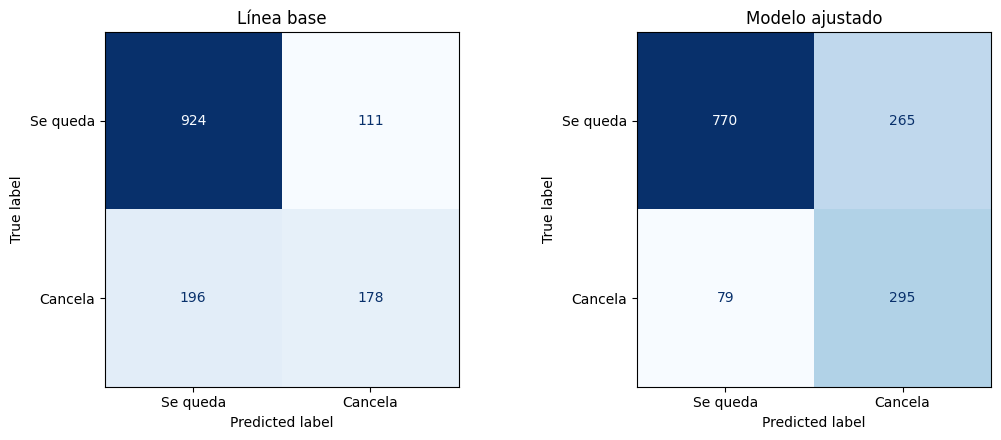

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
# Usamos las predicciones ya calculadas: el test no vuelve a pasar por ningún modelo
for ax, (name, pred) in zip(axes, [("Línea base", baseline_pred), ("Modelo ajustado", final_pred)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Se queda", "Cancela"], cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 8.1 Resultado

**El modelo ajustado detecta 295 de los 374 clientes que cancelan (78,9 %), frente a 178 (47,6 %) de la línea base:
117 cancelaciones más detectadas.**

- **F2: 0,499 → 0,717** (+0,219). El F2 en test (0,717) es casi igual al de validación cruzada (0,723):
  la estimación de la búsqueda era fiable y no hay sobreajuste a los folds.
- **El coste:** la precisión baja de 61,6 % a 52,7 % y las alertas pasan de 289 a 560. Es decir, se ofrecen más retenciones
  a clientes que no las necesitaban. Es justo el intercambio que el negocio considera rentable.
- **La accuracy baja (78,2 % → 75,6 %)**, y eso demuestra por qué no era la métrica adecuada: el modelo "peor" según accuracy
  es el que salva casi el doble de clientes.
- **ROC-AUC sube de 0,818 a 0,844:** el modelo ajustado no solo marca más casos, también **ordena mejor** a los clientes por
  riesgo. La mejora no es solo un cambio de umbral.

In [18]:
final_params = {k.replace("model__", ""): v for k, v in grid_search.best_params_.items()}
print("Hiperparámetros finales:", final_params)
print(f"F2 en CV: {grid_search.best_score_:.4f} ± {best_std:.4f}")
print(f"F2 en test · línea base: {baseline_metrics['F2']:.4f} → ajustado: {final_metrics['F2']:.4f}")
print(f"Recall en test · línea base: {baseline_metrics['Recall']:.4f} → ajustado: {final_metrics['Recall']:.4f}")

Hiperparámetros finales: {'class_weight': 'balanced_subsample', 'max_depth': 6, 'max_features': 0.3, 'min_samples_leaf': 2, 'min_samples_split': 11, 'n_estimators': 144}
F2 en CV: 0.7226 ± 0.0166
F2 en test · línea base: 0.4986 → ajustado: 0.7174
Recall en test · línea base: 0.4759 → ajustado: 0.7888


El resumen completo para el tech lead está en [`tuning_report.md`](tuning_report.md).